# Lezione 1 - Introduzione al Mondo dell'Aspirapolvere

In questo notebook introdurremo il concetto di `ambiente`, `agente` e proveremo a confrontare un `random_agent` con un semplice `reflex agent`.

In [10]:
#  Questo blocco lo eseguo ogni volta all'inizio del notebook per poter accedere ai moduli presenti in scripts
from pathlib import Path
import sys

# Risalgo dalla cartella corrente finché non trovo quella che contiene "scripts"
ROOT = Path.cwd()
while not (ROOT / "scripts").exists():
    ROOT = ROOT.parent

# Aggiungo la root al path di Python, così posso importare i moduli del progetto
sys.path.insert(0, str(ROOT))

# Importo i moduli del corso come scripts.nome_modulo
from scripts.environment import *
from scripts.agent import RandomAgent, Agent
from scripts.runner import run_episode, human_testing

import inspect  # mi serve per stampare il codice sorgente delle classi

## Ambiente

Un **ambiente** è il mondo o il contesto in cui opera un agente. Fornisce percetti (osservazioni) all'agente attraverso i sensori e cambia il suo stato interno in risposta alle azioni eseguite dagli attuatori dell'agente.

Nell'Intelligenza Artificiale (seguendo nello specifico il framework *AIMA* di Russell & Norvig), gli ambienti vengono tipicamente classificati lungo dimensioni chiave:

* **Discreto vs. Continuo:** se gli stati, il tempo o le azioni sono passi distinti o variabili continue.
* **Completamente vs. Parzialmente Osservabile:** se i sensori dell'agente danno accesso completo allo stato dell'ambiente in un dato momento.
* **Deterministico vs. Stocastico:** se lo stato successivo è completamente determinato dallo stato attuale e dall'azione.
* **Statico vs. Dinamico:** se l'ambiente può cambiare mentre l'agente sta deliberando.

### Il Mondo dell'Aspirapolvere

Durante le nostre lezioni di tutoraggio lavoreremo nel Mondo dell'Aspirapolvere, un semplice ambiente a griglia in cui il nostro agente è un aspirapolvere e il nostro obiettivo è pulire tutta la casa. L'ambiente avrà vari livelli di difficoltà. Nel più semplice (0), ci sono solo 2 celle del pavimento disponibili, una sporca e l'altra pulita. Aumentando il livello aumentano il numero di stanze, il numero di possibili ostacoli sul percorso (sia statici che dinamici!) e può persino cambiare il comportamento di pulizia (non tutta la polvere è uguale).

Oggi lavoreremo con la difficoltà 0. Come detto, ci sono 2 celle totali disponibili.

* Il punto blu rappresenta l'aspirapolvere.
* Il punto marrone chiaro rappresenta la sporcizia.

L'aspirapolvere può eseguire fino a 6 azioni diverse:

0. Su (non applicabile in difficoltà 0)
1. Giù (non applicabile in difficoltà 0)
2. Sinistra
3. Destra
4. Idle (inattivo)
5. Aspira

Quando viene selezionata un'azione non legale (es. tentare di muoversi verso un muro o fuori dai limiti), l'aspirapolvere rimane nella sua posizione attuale, ma l'azione viene penalizzata.

Per lavori futuri l'ambiente ha già un sistema di ricompense proxy (che miglioreremo per rendere possibile il reward shaping).

* Movimento Valido (Su, Giù, Sinistra, Destra): $-0.1$
* Movimento Illegale: $-3.0$
* Idle: $-0.5$
* Aspira su Cella Pulita: $-1.0$
* Aspira su Cella Sporca: $+10.0$
* Obiettivo Raggiunto: bonus di $+100.0$ quando tutta la sporcizia è pulita (is_goal() == True), terminando l'episodio (terminated = True).

Inoltre, se l'agente raggiunge il limite di passi (total_step >= max_step), l'episodio termina per troncamento (truncated = True).

> **NOTA** : al momento non ci sono sprite carini per l'ambiente (triste rumore noioso), **ma**, se qualcuno ha del tempo libero da dedicare alla causa, può assolutamente svilupparli. Chiedete direttamente a me per maggiori informazioni. Nessun punto bonus all'esame, solo tanta aura.

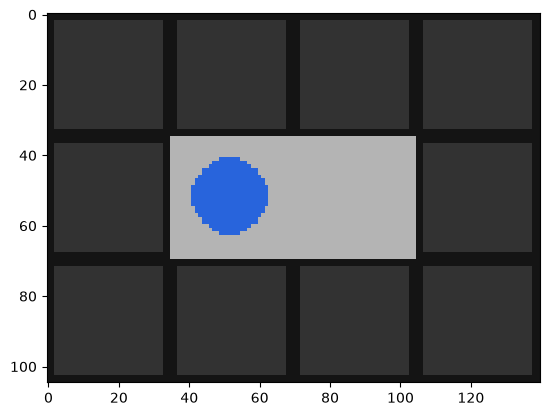

In [11]:
# Creo l'ambiente in difficoltà 0, con osservazione di tipo immagine
env = VacuumWorld(render_mode=RenderMode.RGB_ARRAY, observation_type=ObservationType.IMAGE, difficulty=0)

# Ottengo il frame corrente come array RGB
frame = env._get_obs()

from matplotlib import pyplot as plt

# Mostro il frame
plt.imshow(frame)
plt.show()

Ora, vi lascio provare l'ambiente prima di andare avanti.

I tasti associati per l'umano sono:

* Q per aspirare
* WASD per muoversi
* niente per rimanere inattivo

In [12]:
from scripts.runner import human_testing

# Creo un ambiente in difficoltà 1 e lo gioco manualmente da tastiera
env = VacuumWorld(difficulty=1)
human_testing(env)

## Osservazione

Ci sono due possibili tipi di osservazioni:

* **grid**
* **image**

**Image** è quella mostrata prima.

In realtà, per ora useremo solo l'**osservazione grid**.\
Cos'è l'osservazione grid? L'osservazione grid è una **matrice** in formato $(x, y)$.\
Ogni valore della griglia rappresenta una condizione specifica:

* 0 : cella libera
* 1 : cella sporca
* 2 : muro
* 3 : aspirapolvere
* 3.5 : aspirapolvere con una cella sporca sotto

In [13]:
# Creo l'ambiente con osservazione di tipo grid (matrice di valori)
env = VacuumWorld(render_mode=RenderMode.RGB_ARRAY, observation_type=ObservationType.GRID, difficulty=0)

# Estraggo la griglia corrente
grid = env._get_obs()

# La stampo a video per vedere i valori
grid

array([[2. , 2. , 2. , 2. ],
       [2. , 0. , 3.5, 2. ],
       [2. , 2. , 2. , 2. ]], dtype=float32)

## Agente

Un agente, come definito nel capitolo 2.1 del libro *Artificial Intelligence: A Modern Approach*, è qualsiasi cosa che può percepire il proprio ambiente attraverso i sensori e agire su di esso attraverso gli attuatori, in base al proprio programma di agente. Può essere un cane, un robot o persino voi. Finché potete percepire l'ambiente e agire su di esso, siete un agente. Questo notebook spiegherà come implementare un semplice agente, creare un ambiente e implementare un programma che aiuti l'agente ad agire sull'ambiente in base ai suoi percetti.

Useremo un oggetto della classe `Agent`. Importiamolo.

### Agente Casuale

Un programma di agente casuale, come suggerisce il nome, sceglie un'azione a caso, senza tenere conto dei percetti.\
Qui dimostreremo un agente aspirapolvere casuale per un ambiente aspirapolvere banale, cioè l'ambiente a due stati.

In [5]:
print(inspect.getsource(RandomAgent))

class RandomAgent(Agent):
    """Random agent."""

    def __init__(self, env : gym.Env):
        """Just take the actions from the enviornment as basic knowledge"""
        self.action_space = env.action_space

    def act(self, observation: Any):
        """Observation are not actually used"""
        return self.action_space.sample()



Quindi, cosa fa il nostro `RandomAgent`?\
Beh, praticamente si inizializza prendendo le possibili azioni (tutte) e quando deve agire, agisce semplicemente a caso.

Non spaventatevi per `gym.Env`: in questa serie di notebook useremo il **Protocollo Gymnasium**, un protocollo ben consolidato per gestire agenti (specialmente in scenari di Reinforcement Learning, ma lo adatteremo). Potete trovare maggiori informazioni in [questa documentazione qui](https://gymnasium.farama.org/introduction/basic_usage/).

Quindi non preoccupatevene e vediamo l'agente in azione!

Renderizziamo la scena con PyGame. Personalmente lo trovo davvero piacevole, magari date un'occhiata alla sua [documentazione qui](https://www.pygame.org/docs/).

In [14]:
# Creo un ambiente di default
env = VacuumWorld()

# Istanzio l'agente casuale passandogli l'ambiente
agent = RandomAgent(env)

# Eseguo un episodio completo e restituisco la ricompensa totale
run_episode(env, agent)

54.599999999999994

### Agente Riflesso Semplice

Un programma di agente riflesso semplice seleziona le azioni sulla base del percetto corrente, ignorando il resto della storia dei percetti.\
Questi agenti funzionano con una regola condizione-azione (chiamata anche regola situazione-azione, produzione o regola if-then), che indica all'agente l'azione da attivare quando si verifica una particolare situazione.

In [15]:
class ReflexAgent(Agent):
    def __init__(self, env):
        super().__init__(env)

    def act(self, observation):
        my_pos = (0, 0)

        # Cerco la mia posizione nella griglia
        for x, row in enumerate(observation):
            for y, el in enumerate(row):
                if el == 3.5: # Sono su una cella sporca → la aspiro subito
                    return 5
                if el == 3:   # Sono su una cella pulita → salvo la mia posizione
                    my_pos = (x, y)

        # Definisco le direzioni come azioni (0=SU, 1=SINISTRA, 2=GIÙ, 3=DESTRA)
        directions = { 
                       0 : (0, -1),  # SU
                       1 : (-1, 0),  # SINISTRA
                       2 : (0, 1),   # GIÙ
                       3 : (1, 0)    # DESTRA
                    }   
        
        # Se una cella sporca è adiacente, mi muovo verso di essa
        for act in directions:
            dir = directions[act]
            new_x = my_pos[0] - dir[0]
            new_y = my_pos[1] - dir[1]
            if observation[new_x, new_y] == 1:
                return act
            
        # Altrimenti mi muovo verso la cella pulita più vicina
        for act in directions:
                    dir = directions[act]
                    new_x = my_pos[0] - dir[0]
                    new_y = my_pos[1] - dir[1]
                    if observation[new_x, new_y] == 0:
                        return act

        # Non dovrei mai arrivare qui, ma se succede rimango inattivo
        print("Siamo finiti qui stranamente. Rimaniamo inattivi.")
        return 4
        

Vediamo il vostro agente in azione!

In [18]:
# Creo l'ambiente in difficoltà 0
env = VacuumWorld(difficulty=0)

# Istanzio il mio agente riflesso
agent = ReflexAgent(env)

# Eseguo un episodio e vedo il punteggio totale
run_episode(env, agent)

-882.0

Riuscite a battere la difficoltà 1?

In [17]:
env = VacuumWorld(difficulty=1)
agent = ReflexAgent(env)
run_episode(env, agent)

-1771.0

#### Con l'implementazione qui sotto non è (sempre) possibile. <span style="color:red">*Perché? Sapete spiegarlo?*</span>


Il `ReflexAgent` fallisce (o comunque non riesce sempre) in difficoltà 1 per una serie di motivi legati alla natura stessa degli agenti riflessi semplici:

1. **Nessuna memoria.** Decide solo in base al percetto corrente, quindi non ricorda dove è già passato né quali celle ha già pulito. Può tornare più volte sulle stesse celle, sprecando passi e ricompensa.

2. **Nessuna pianificazione.** Non ha un modello del mondo e non può calcolare un percorso verso una cella sporca che non è adiacente. Si limita a muoversi verso la prima cella pulita disponibile, che potrebbe allontanarlo dall'obiettivo.

3. **Regole locali troppo rigide.** Le regole "se c'è sporco adiacente, vacci" e "altrimenti muoviti su una cella pulita" funzionano nel caso banale a 2 celle, ma in un ambiente più grande portano facilmente a **loop infiniti** (oscillare tra due celle pulite) o a **bloccarsi** contro un ostacolo senza trovare una via alternativa.

4. **Ostacoli dinamici.** La difficoltà 1 introduce ostacoli che possono muoversi. Un agente riflesso non può prevederne il movimento né adattare il proprio comportamento, quindi può rimanere intrappolato o non riuscire a raggiungere tutte le celle sporche.

5. **Nessuna priorità.** Se ci sono più celle sporche, l'agente non sa quale convenga pulire prima: sceglie in base all'ordine arbitrario delle direzioni nel dizionario.

**In sintesi:** il `ReflexAgent` è adatto solo ad ambienti **piccoli, statici e completamente osservabili** come la difficoltà 0. Per affrontare la difficoltà 1 servono agenti con **stato interno** (memoria), capacità di **pianificazione**, o almeno un **modello** dell'ambiente — come gli agenti basati su modello o gli agenti con ricerca.